# 05 · Height validation against G-LiHT, by height class

**Question:** are reclassified 30 m heights closer to G-LiHT than the current v7 segments, across height classes from tundra
shrubs to tall Kenai forest?

Reference for each segment: the 1 m G-LiHT CHM inside the segment footprint (30 m along track × 11 m), after the track's
horizontal shift from notebook 02. Main reference metric: CHM 98th percentile (RH98, config `validation.als_reference_percentile`);
RH90–RH100 are also compared because the best-matching ALS percentile for ICESat-2 is not fixed (Zhang & Liu 2023 found RH95).
Segments with > 10 % disturbed photons (Hansen loss in or after the ALS year) are excluded. Seward segments (UAV reference,
notebook 01) are added for the 0–2 m classes.

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes (v0.1)** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds in `config/atl03_reclass_v0.1.yaml`. |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments (ATL08-style along-track segments), three versions from the same photons**
| Term | Photon classes used | 30 m binning | Role |
|---|---|---|---|
| **current v7 30 m (ATL08 classes → PhoREAL)** | ATL08 v007 | SlideRule PhoREAL (as in `process_atl08_boreal.py`) | What our training files contain today |
| **ATL08 classes → our 30 m (check)** | ATL08 v007 | ours (`segment_metrics`) | Check: separates the effect of our binning from our classification |
| **reclassified photons → our 30 m (new)** | reclassified v0.1 | ours (`segment_metrics`) | The new product being tested |

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.1.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)
FIG = WORK / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.1 d49984a76293 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "7d697cc",
 "git_dirty_lib_or_config": true,
 "config_version": "0.1",
 "config_sha1": "d49984a76293",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-15T08:56:51"
}


## Reference height for every segment

**Input:** the matched segments (notebook 04), the G-LiHT CHM strips and the track shifts (notebook 02).

**What happens:** each segment becomes a footprint rectangle (first to last photon, 11 m wide), shifted by its track's
horizontal offset; the 1 m CHM values inside it give the **reference height** (CHM RH98) and other percentiles and cover
fractions (`lib: segment_footprints, als_segment_metrics`). Segments with more than 10 % disturbed photons are dropped.
Seward segments (UAV reference, notebook 01) are added.

**Output:** `validation/tile_<n>_segments_als.parquet`.

In [2]:
GL = WORK / "glihit"; SEG = WORK / "segments"; OUT = WORK / "validation"; OUT.mkdir(exist_ok=True)
parts = []
for fn in sorted(SEG.glob("tile_*_segments.parquet")):
    t = int(fn.name.split("_")[1])
    s = gpd.read_parquet(fn)
    fpo = OUT / f"tile_{t}_segments_als.parquet"
    if fpo.exists():
        parts.append(gpd.read_parquet(fpo)); continue
    strips = pd.read_csv(GL / f"tile_{t}" / "strips.csv")
    off = pd.read_csv(GL / f"tile_{t}" / "offsets.csv").set_index("track_id")
    fps = ref.segment_footprints(s, cfg["validation"]["segment_footprint_width_m"])
    out = []
    for tid, g in fps.groupby("track_id"):
        dx, dy = (off.loc[tid, "dx"], off.loc[tid, "dy"]) if tid in off.index else (0.0, 0.0)
        out.append(ref.als_segment_metrics(g, strips.chm.tolist(), dx, dy, percentiles=(50, 75, 90, 95, 98, 100)))
    a = gpd.GeoDataFrame(pd.concat(out), crs=fps.crs).to_crs(4326)
    ipl.write_parquet(a, fpo, ipl.provenance(cfg, tile_num=t))
    parts.append(a)
v = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=4326)
v = v[(v.als_n > 0) & (v.disturbed_frac.fillna(0) <= 0.10)]
sew = pd.concat([gpd.read_parquet(f) for f in sorted((WORK / "seward").glob("*_segments.parquet"))], ignore_index=True)
sew = sew[sew.als_n > 0].assign(region="Seward")
val_all = pd.concat([v, sew], ignore_index=True)
print(val_all.groupby("region").size())

region
Interior    18442
Kenai        6906
Seward        473
dtype: int64


## Which G-LiHT height percentile does each version track?

`h_canopy` is the 98th percentile of canopy photons, but sparse photons rarely hit the very top of the canopy, so ICESat-2
heights may match a lower percentile of the lidar CHM (Zhang & Liu 2023 found RH95). Bias, RMSE and correlation of each 30 m
version against the CHM RH90, RH95, RH98 and RH100 inside the segment footprints.

In [3]:
schemes = {val.LABEL_CURRENT: "h_canopy_phoreal", val.LABEL_CHECK: "h_canopy_atl08", val.LABEL_NEW: "h_canopy"}
rows = []
for k, c in schemes.items():
    for p in (90, 95, 98, 100):
        d = val_all[[c, f"als_rh{p}"]].dropna()
        e = d[c] - d[f"als_rh{p}"]
        rows.append({"scheme": k, "als": f"RH{p}", "n": len(d), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean()), "r": d.corr().iat[0, 1]})
pd.DataFrame(rows).pivot(index="als", columns="scheme", values=["bias", "rmse", "r"]).round(2)

bias  \
scheme ATL08 classes → our 30 m (check)   
als                                       
RH100                              0.93   
RH90                               3.59   
RH95                               2.86   
RH98                               2.12   

                                                  \
scheme current v7 30 m (ATL08 classes → PhoREAL)   
als                                                
RH100                                      -0.86   
RH90                                        1.46   
RH95                                        0.84   
RH98                                        0.19   

                                                                         rmse  \
scheme reclassified photons → our 30 m (new) ATL08 classes → our 30 m (check)   
als                                                                             
RH100                                  -3.43                             7.59   
RH90                                   -1.16                             7.39   
RH95                                   -1.77                             7.32   
RH98                                   -2.40                             7.36   

                                                  \
scheme current v7 30 m (ATL08 classes → PhoREAL)   
als                                                
RH100                                       8.02   
RH90                                        7.35   
RH95                                        7.40   
RH98                                        7.58   

                                                                            r  \
scheme reclassified photons → our 30 m (new) ATL08 classes → our 30 m (check)   
als                                                                             
RH100                                   7.97                             0.41   
RH90                                    6.04                             0.46   
RH95                                    6.50                             0.45   
RH98                                    7.05                             0.43   

                                                  \
scheme current v7 30 m (ATL08 classes → PhoREAL)   
als                                                
RH100                                       0.41   
RH90                                        0.43   
RH95                                        0.43   
RH98                                        0.43   

                                              
scheme reclassified photons → our 30 m (new)  
als                                           
RH100                                   0.36  
RH90                                    0.42  
RH95                                    0.41  
RH98                                    0.39

## Error by reference height class (reference height = G-LiHT/UAV CHM RH98 in the footprint)

Top: each 30 m version against the reference height. Bottom: mean bias and RMSE per reference-height class, and the
spurious-vegetation rate (reference < 1 m, ICESat-2 > 2 m). In the reclassified version, segments set to 0 m by the
short-vegetation guard count as 0 m here.

n    bias  \
scheme                                    height_class                        
current v7 30 m (ATL08 classes → PhoREAL) 0-1 m              1061.0   3.192   
                                          1-2 m               281.0   1.662   
                                          2-5 m               424.0   1.043   
                                          5-10 m              362.0  -1.282   
                                          10-15 m             251.0  -3.736   
                                          15-20 m             260.0  -5.257   
                                          20+ m               113.0  -8.869   
                                          all                2752.0   0.191   
                                          spurious_veg_rate  1061.0   0.372   
ATL08 classes → our 30 m (check)          0-1 m               652.0   6.997   
                                          1-2 m               218.0   5.382   
                                          2-5 m               396.0   2.322   
                                          5-10 m              329.0   0.611   
                                          10-15 m             245.0  -2.152   
                                          15-20 m             257.0  -3.703   
                                          20+ m               110.0  -6.305   
                                          all                2207.0   2.122   
                                          spurious_veg_rate   652.0   0.678   
reclassified photons → our 30 m (new)     0-1 m              1229.0   1.381   
                                          1-2 m               312.0   0.255   
                                          2-5 m               460.0  -1.418   
                                          5-10 m              398.0  -4.518   
                                          10-15 m             274.0  -8.075   
                                          15-20 m             275.0  -9.974   
                                          20+ m               124.0 -14.021   
                                          all                3072.0  -2.398   
                                          spurious_veg_rate  1229.0   0.206   

                                                               rmse     mae  \
scheme                                    height_class                        
current v7 30 m (ATL08 classes → PhoREAL) 0-1 m               9.086   3.296   
                                          1-2 m               4.552   2.405   
                                          2-5 m               5.357   2.734   
                                          5-10 m              5.630   3.673   
                                          10-15 m             5.875   4.700   
                                          15-20 m             7.765   5.973   
                                          20+ m              12.104   9.080   
                                          all                 7.576   3.786   
                                          spurious_veg_rate     NaN     NaN   
ATL08 classes → our 30 m (check)          0-1 m               9.628   7.020   
                                          1-2 m               8.359   5.569   
                                          2-5 m               5.540   3.459   
                                          5-10 m              5.021   3.788   
                                          10-15 m             5.157   3.963   
                                          15-20 m             5.499   4.127   
                                          20+ m               9.070   6.406   
                                          all                 7.357   5.049   
                                          spurious_veg_rate     NaN     NaN   
reclassified photons → our 30 m (new)     0-1 m               4.546   1.685   
                                          1-2 m               4.512   2.005   
                                    

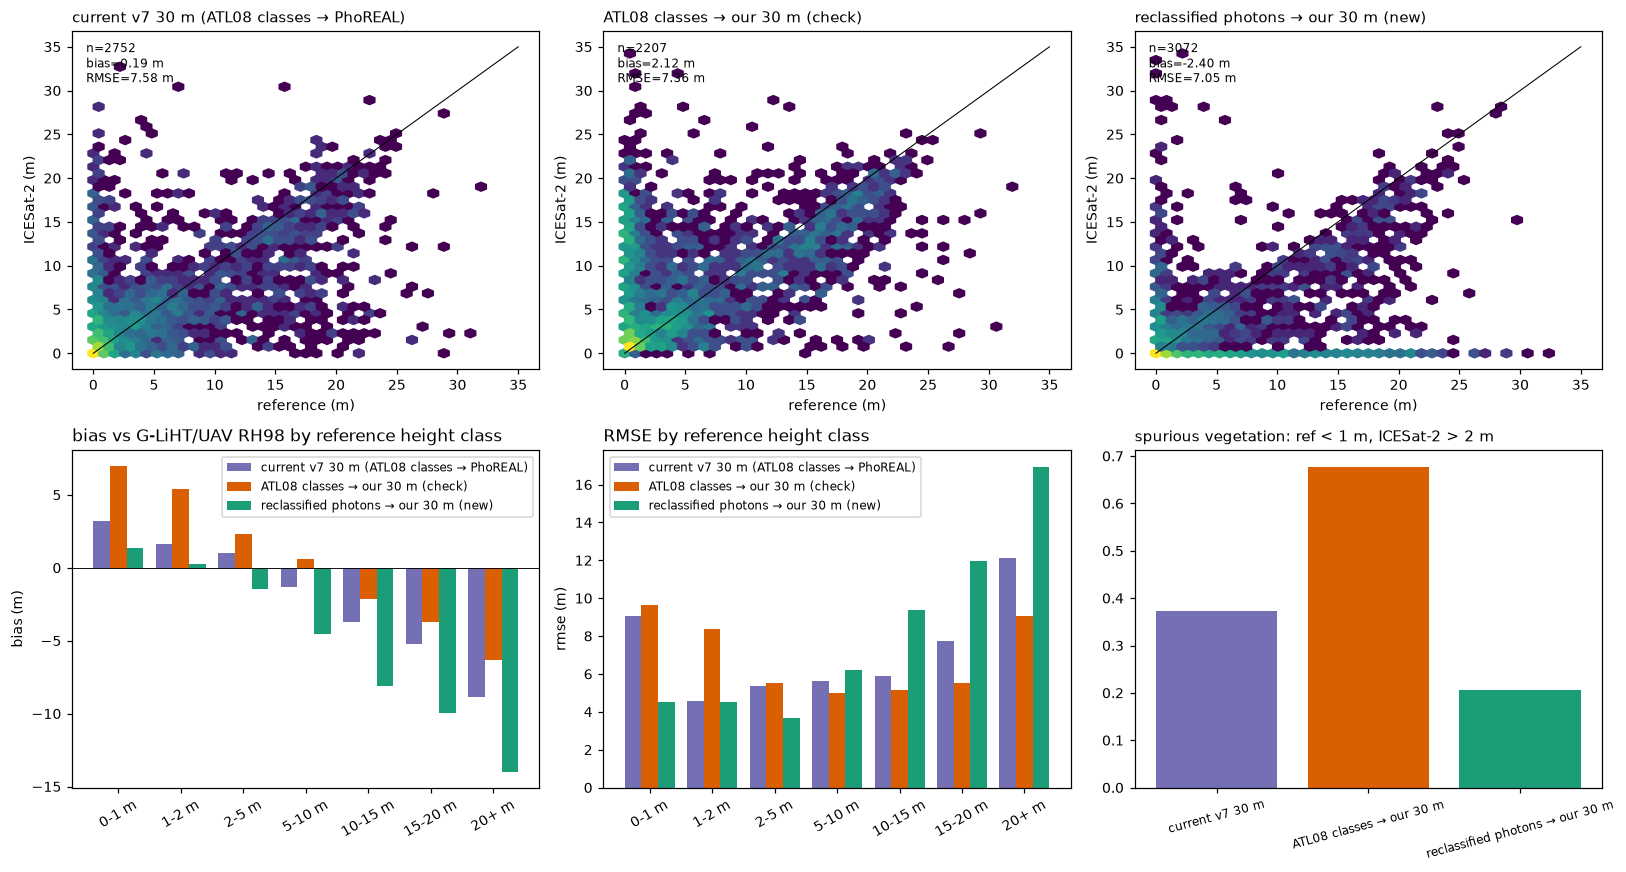

In [4]:
edges = cfg["validation"]["height_classes_m"]
REF = f"als_rh{cfg['validation']['als_reference_percentile']}"
tabs = {k: val.metrics_by_height_class(val_all[c], val_all[REF], edges, cfg["validation"]["spurious_veg"]) for k, c in schemes.items()}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (k, c) in zip(axes[0], schemes.items()):
    val.plot_scatter(ax, val_all[c], val_all[REF], k, lim=35)
val.plot_bias_by_class(tabs, f"bias vs G-LiHT/UAV {REF.upper()[4:]} by reference height class", axes[1, 0], "bias")
val.plot_bias_by_class(tabs, "RMSE by reference height class", axes[1, 1], "rmse")
sp = pd.Series({k: t.loc["spurious_veg_rate", "bias"] for k, t in tabs.items()})
axes[1, 2].bar(range(len(sp)), sp.values, color=[val.SCHEME_COLORS[k] for k in sp.index])
axes[1, 2].set_xticks(range(len(sp)), [k.split(" (")[0] for k in sp.index], rotation=15, fontsize=8)
axes[1, 2].set_title("spurious vegetation: ref < 1 m, ICESat-2 > 2 m", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "05_height_validation.png", dpi=150)
summary = pd.concat(tabs, names=["scheme", "height_class"]).round(3)
summary.to_csv(OUT / "height_validation_by_class.csv")
summary

## By region, day vs night, and beam strength

Mean bias of each 30 m version against the reference height, split by region (Interior, Kenai, Seward), by solar elevation,
and by beam strength.

bias  \
scheme          ATL08 classes → our 30 m (check)   
by     group                                       
beam   strong                               1.65   
       weak                                 3.00   
light  day                                  3.07   
       night                               -0.20   
region Interior                             2.42   
       Kenai                                0.76   
       Seward                               4.77   

                                                           \
scheme          current v7 30 m (ATL08 classes → PhoREAL)   
by     group                                                
beam   strong                                        0.53   
       weak                                         -0.38   
light  day                                          -0.25   
       night                                         1.19   
region Interior                                     -0.08   
       Kenai                                        -0.23   
       Seward                                        2.11   

                                                       \
scheme          reclassified photons → our 30 m (new)   
by     group                                            
beam   strong                                   -1.59   
       weak                                     -3.78   
light  day                                      -2.36   
       night                                    -2.48   
region Interior                                 -1.48   
       Kenai                                    -4.04   
       Seward                                    0.09   

                                            rmse  \
scheme          ATL08 classes → our 30 m (check)   
by     group                                       
beam   strong                               6.53   
       weak                                 8.68   
light  day                                  7.82   
       night                                6.07   
region Interior                             7.23   
       Kenai                                7.39   
       Seward                               7.52   

                                                           \
scheme          current v7 30 m (ATL08 classes → PhoREAL)   
by     group                                                
beam   strong                                        6.78   
       weak                                          8.77   
light  day                                           6.35   
       night                                         9.81   
region Interior                                      5.60   
       Kenai                                         9.65   
       Seward                                        4.55   

                                                       
scheme          reclassified photons → our 30 m (new)  
by     group                                           
beam   strong                                    6.69  
       weak                                      7.63  
light  day                                       6.99  
       night                                     7.19  
region Interior                                  5.86  
       Kenai                                     8.77  
       Seward                                    2.93

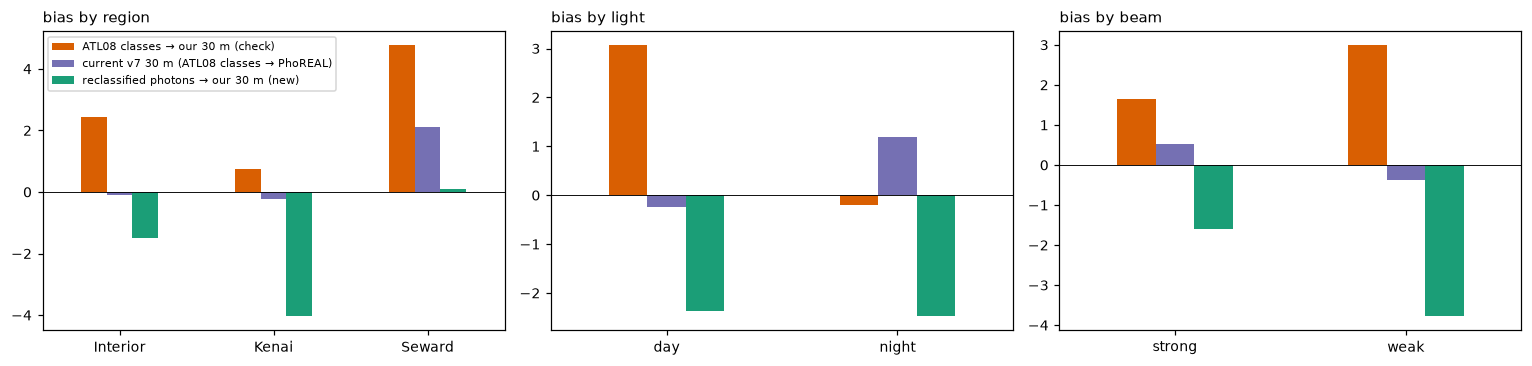

In [5]:
val_all["light"] = np.where(val_all.solar_elevation > 0, "day", "night")
val_all["beam"] = np.where(val_all.strong, "strong", "weak")
rows = []
for by in ["region", "light", "beam"]:
    for grp, g in val_all.groupby(by):
        for k, c in schemes.items():
            d = g[[c, REF]].dropna(); e = d[c] - d[REF]
            rows.append({"by": by, "group": grp, "scheme": k, "n": len(d), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean())})
t = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, by in zip(axes, ["region", "light", "beam"]):
    tt = t[t.by == by].pivot(index="group", columns="scheme", values="bias")
    tt.plot.bar(ax=ax, color=[val.SCHEME_COLORS[c] for c in tt.columns], legend=(by == "region"), rot=0)
    ax.axhline(0, c="k", lw=0.6); ax.set_title(f"bias by {by}", loc="left", fontsize=10); ax.set_xlabel("")
axes[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "05_bias_by_group.png", dpi=150)
t.pivot_table(index=["by", "group"], columns="scheme", values=["bias", "rmse"]).round(2)

## Results
Summarise after review: bias and RMSE per height class for the three versions; the spurious-vegetation rate; whether the tall
classes are less underestimated after reclassification; differences by day/night and beam strength.